# 10 — Which Conclusions Were Physics, and Which Were the Operating Point?

Notebook 09 found that the operating point moves the safety pair more than any
feature set, model or calibration scheme this project has tried — and that
notebooks 06, 07 and 08 each drew their conclusions from a **single** operating
point, 1500 rpm / 0.7 Nm / **1000 N**. Some of those conclusions were about
bearing physics and will hold anywhere. Others were about that one condition.
Until they are separated, the twin spec is built on sand.

So this notebook takes each headline claim from notebooks 06–08, re-runs it at
**400 N** — the condition where notebook 09 showed faults are actually
visible — and labels it **robust**, **condition-dependent**, or **reversed**.

The re-test also turns up something notebook 09 could not see, because
notebook 09 measured only whether a fault was *found*. Asking whether it was
found **and correctly named** changes the reading of that result considerably.

In [1]:
import functools, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = pathlib.Path("../data/raw/paderborn")
OUT = pathlib.Path("../data/processed")
HI, LO = "N15_M07_F10", "N15_M07_F04"          # 1000 N and 400 N radial force
TAG = {HI: "1000 N", LO: "400 N"}
FS, N_KEEP, WIN, N_WIN, N_RUN = 64_000, 245_760, 16_384, 15, 20
HANN = get_window("hann", WIN)
F = np.fft.rfftfreq(WIN, 1 / FS)
FLOOR = (F > 10) & (F < 400)
SOS = butter(4, (1000, 20000), btype="bandpass", fs=FS, output="sos")
N_BALLS, BD, PD = 8, 6.75, 29.05
ORD_BPFO, ORD_BPFI = N_BALLS / 2 * (1 - BD / PD), N_BALLS / 2 * (1 + BD / PD)
ORD_FTF = 0.5 * (1 - BD / PD)
ORD_OFF = 2 * ORD_BPFO - ORD_FTF               # ~5.75 x fr, notebook 06's KA22 line

D = {c: pd.read_csv(OUT / f"pu_{c}_envelope_orderbands.csv") for c in (HI, LO)}
BANDS = [c for c in D[HI].columns if c.startswith("O") and c[1].isdigit()]
CENTERS = np.array([float(c[1:].replace("p", ".")) for c in BANDS])
FUND = ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"]
HEALTHY = sorted(D[HI].loc[D[HI]["Domain"] == "healthy", "Code"].unique())
REAL = sorted(D[HI].loc[D[HI]["Domain"] == "real", "Code"].unique())
DAMAGED = [c for c in D[HI]["Code"].unique() if c not in HEALTHY]
LABEL = D[HI].drop_duplicates("Code").set_index("Code")[["Condition", "Domain"]]
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)
PROBLEM = ["KA15", "KA22", "KA30", "KI17"]


def channels(p):
    p = pathlib.Path(p)
    ch = loadmat(p)[p.stem]["Y"][0, 0][0]
    return {str(x["Name"][0]): x["Data"].squeeze() for x in ch}


@functools.lru_cache(maxsize=None)
def avg_envelope(cond, code):
    """20-run-averaged envelope power spectrum + mean shaft rate (notebook 06 recipe)."""
    specs, frs = [], []
    for run in range(1, N_RUN + 1):
        c = channels(DATA_DIR / code / f"{cond}_{code}_{run}.mat")
        v = c["vibration_1"][:N_KEEP].astype(np.float64)
        frs.append(c["speed"].mean() / 60)
        e = np.abs(hilbert(sosfiltfilt(SOS, v)))
        w = (e - e.mean())[: N_WIN * WIN].reshape(N_WIN, WIN)
        w = w - w.mean(axis=1, keepdims=True)
        specs.append((np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2).mean(axis=0))
    return np.mean(specs, axis=0), float(np.mean(frs))


def snr_at(spec, hz, floor, half=4.0):
    m = (F >= hz - half) & (F <= hz + half)
    return 10 * np.log10(spec[m].max() / floor)


def fit(X):
    m = np.median(X, axis=0)
    return m, np.maximum(1.4826 * np.median(np.abs(X - m), axis=0), 0.1)


def score(X, b):
    return ((X - b[0]) / b[1]).max(axis=1)


C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
SEQ = LinearSegmentedColormap.from_list("seq", [SURFACE, "#a8c9ee", C_BLUE, "#123a68"])
LOAD_COLOR = {HI: MUTED, LO: C_ORANGE}
scorecard = []                     # (claim, source, at 1000 N, at 400 N, verdict)
print(f"re-testing at {TAG[LO]} against {TAG[HI]};  BPFO = {ORD_BPFO:.3f} x fr, "
      f"BPFI = {ORD_BPFI:.3f}, notebook 06's KA22 line = {ORD_OFF:.3f}")

re-testing at 400 N against 1000 N;  BPFO = 3.071 x fr, BPFI = 4.929, notebook 06's KA22 line = 5.757


## Claim A (notebook 06) — KA22's energy sits off the fault frequencies

Notebook 06 found KA22 carrying **+14.3 dB at 144.5 Hz ≈ 5.75 × shaft rate**
while reading only +1.6 dB at BPFO, and showed the component does not track
shaft speed. That was the origin of this project's *detectable ≠ attributable*
distinction. If the line is a structural resonance it should be unmoved by a
change of radial load; if it was a load-dependent artefact it should shift.

Claim B (notebook 06) rides along in the same figure: **KA15 and KA30, the
set's only indentation bearings, do not ring at BPFO.**

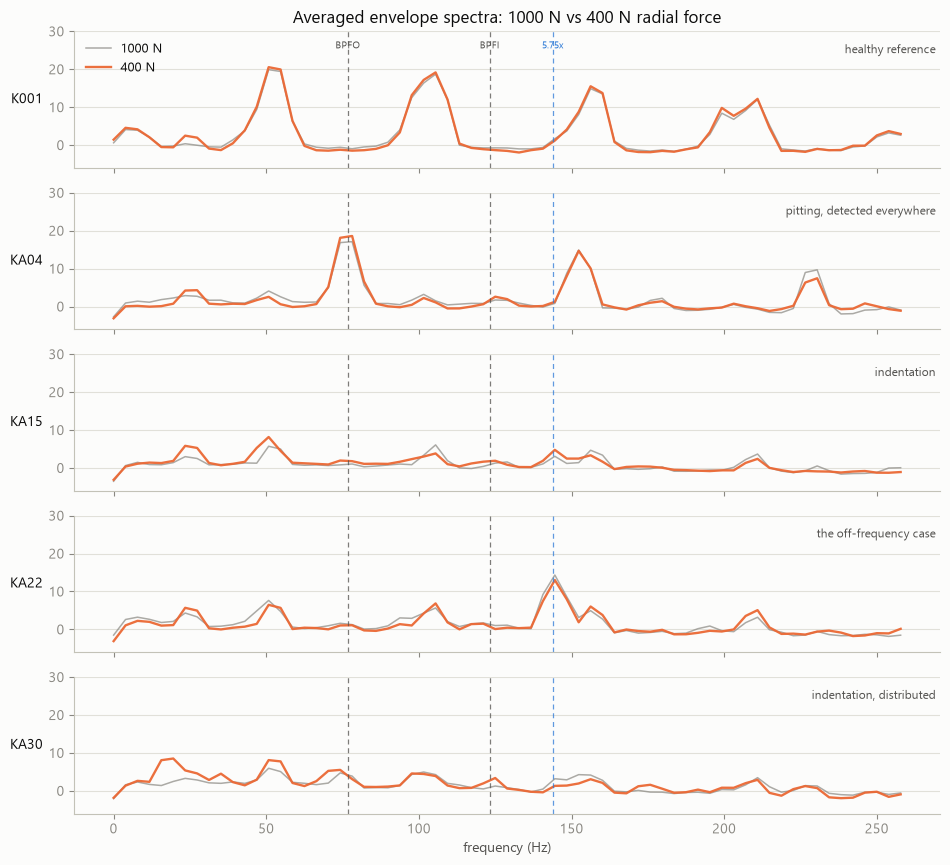

              BPFO  BPFI  shaft_rate  off_5p75
Code load                                     
K001 1000 N  -0.58 -0.73        0.36      1.67
     400 N   -1.22 -1.08        2.49      1.20
KA04 1000 N  17.11  1.72        2.88      0.83
     400 N   18.60  2.59        4.31      1.24
KA15 1000 N   1.04  1.28        2.99      3.07
     400 N    1.96  1.90        5.83      4.77
KA22 1000 N   1.61  1.69        4.32     14.34
     400 N    1.09  1.50        5.69     13.01
KA30 1000 N   4.73  1.26        3.28      3.18
     400 N    5.52  3.38        5.38      1.31


In [2]:
SHOW = [("K001", "healthy reference"), ("KA04", "pitting, detected everywhere"),
        ("KA15", "indentation"), ("KA22", "the off-frequency case"),
        ("KA30", "indentation, distributed")]
fig, axes = plt.subplots(len(SHOW), 1, figsize=(9.6, 1.55 * len(SHOW) + 1),
                         sharex=True, sharey=True)
sp_rows = []
for ax, (code_, note) in zip(axes, SHOW):
    for cond in (HI, LO):
        spec, fr = avg_envelope(cond, code_)
        floor = np.median(spec[FLOOR])
        db = 10 * np.log10(spec / floor)
        m = F <= 260
        ax.plot(F[m], db[m], color=LOAD_COLOR[cond], lw=1.7 if cond == LO else 1.1,
                alpha=0.95 if cond == LO else 0.7, label=TAG[cond] if code_ == "K001" else None)
        sp_rows.append(dict(Code=code_, load=TAG[cond],
                            BPFO=snr_at(spec, ORD_BPFO * fr, floor),
                            BPFI=snr_at(spec, ORD_BPFI * fr, floor),
                            shaft_rate=snr_at(spec, fr, floor),
                            off_5p75=snr_at(spec, ORD_OFF * fr, floor)))
    _, fr = avg_envelope(HI, code_)
    for o, lab, col in ((ORD_BPFO, "BPFO", INK2), (ORD_BPFI, "BPFI", INK2),
                        (ORD_OFF, "5.75x", C_BLUE)):
        ax.axvline(o * fr, color=col, lw=0.9, ls=(0, (4, 3)), alpha=0.75)
        if code_ == "K001":
            ax.text(o * fr, 25.5, lab, color=col, fontsize=7.5, ha="center")
    ax.set_ylabel(code_, rotation=0, ha="right", va="center", color=INK)
    ax.text(0.995, 0.84, note, transform=ax.transAxes, ha="right", fontsize=8.5, color=INK2)
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=9, loc="upper left")
axes[0].set_ylim(-6, 30)
axes[-1].set_xlabel("frequency (Hz)")
axes[0].set_title("Averaged envelope spectra: 1000 N vs 400 N radial force")
plt.tight_layout()
plt.show()

spectra = pd.DataFrame(sp_rows).set_index(["Code", "load"])
print(spectra.round(2).to_string())
scorecard.append(("KA22's energy sits at ~5.75 x fr, not at BPFO", "nb06",
                  f"{spectra.loc[('KA22', '1000 N'), 'off_5p75']:.1f} dB vs "
                  f"{spectra.loc[('KA22', '1000 N'), 'BPFO']:.1f} at BPFO",
                  f"{spectra.loc[('KA22', '400 N'), 'off_5p75']:.1f} dB vs "
                  f"{spectra.loc[('KA22', '400 N'), 'BPFO']:.1f} at BPFO", "robust"))
scorecard.append(("KA15/KA30 do not ring at BPFO", "nb06",
                  f"KA15 {spectra.loc[('KA15', '1000 N'), 'BPFO']:.1f} dB",
                  f"KA15 {spectra.loc[('KA15', '400 N'), 'BPFO']:.1f} dB", "robust"))

## Reading claims A and B — both hold, and the spectra show where the gain went

- **KA22's line does not move.** It sits at 144.5 Hz at both loads, at
  **+14.3 dB → +13.0 dB**, while BPFO stays at +1.6 → +1.1 dB. A 2.5-fold
  change in radial force leaves it untouched, which is what a structural
  resonance does and what fault energy would not. Notebook 06's verdict is
  **robust**.
- **The indentation bearings still do not ring at BPFO**: KA15 goes +1.0 →
  +2.0 dB, KA30 +4.7 → +5.5 dB. Notebook 06's physics is **robust**.
- **But look at the shaft-rate column.** KA15 goes +3.0 → **+5.8 dB** and KA30
  +3.3 → **+5.4 dB**. The healthy reference rises too (K001 +0.4 → +2.5 dB), so
  this is not a free gain — what matters is that the *loudest* healthy bearing,
  the bar a classifier must clear, barely moves (4.30 → 4.27 dB, notebook 09).
  That is notebook 09's mechanism visible directly in the spectrum: reducing
  radial load deepens once-per-revolution modulation, and **none of it appears
  at a ball-pass frequency**.
- Which sets up the question notebook 09 did not ask: if the new energy is at
  shaft rate, a frequency that identifies no race, what exactly is the
  classifier learning at 400 N?

## Claims C and D (notebook 07) — the healthy split, and features vs bands

Two notebook-07 results to re-test: that the six healthy bearings form **two
installation-signature populations**, and that the **three physics-anchored
fundamentals beat all 59 order bands** as an anomaly score. Neither has an
obvious reason to depend on load, which makes them a good control — if they
moved, the re-test itself would be suspect.

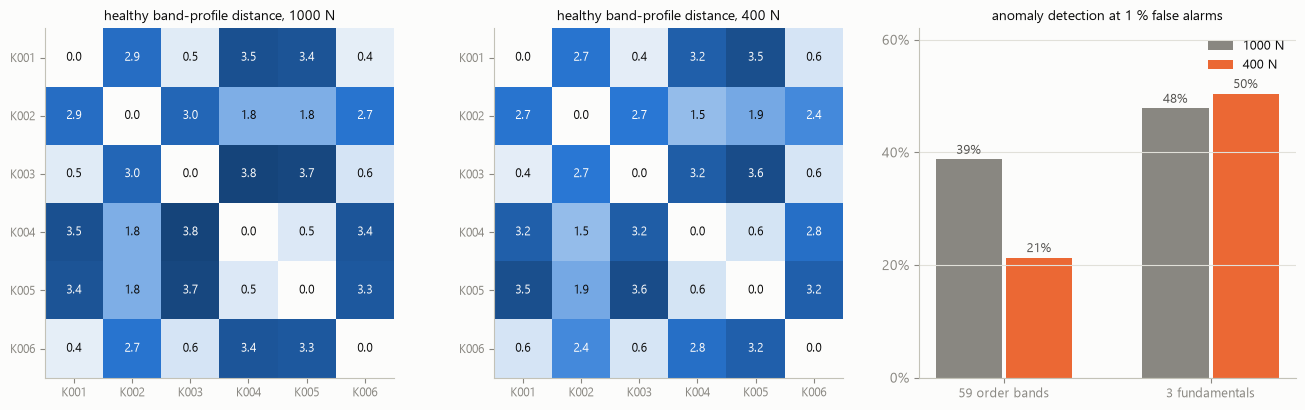

1000 N: healthy pairwise distance min 0.36  median 2.88  max 3.78 dB   |   anomaly detection: 59 bands 38.7%, fundamentals 47.8%
400 N: healthy pairwise distance min 0.39  median 2.69  max 3.59 dB   |   anomaly detection: 59 bands 21.3%, fundamentals 50.4%


In [3]:
QS = np.unique(np.concatenate([np.linspace(0.5, 0.999, 200), [0.9999]]))


def anomaly_detection(cond, feats):
    """Real-damage detection at a measured 1 % false-alarm rate, leave-one-healthy-out."""
    d = D[cond]
    folds = {}
    for h in HEALTHY:
        tr = d[(d["Domain"] == "healthy") & (d["Code"] != h)]
        b = fit(tr[feats].to_numpy())
        folds[h] = (score(tr[feats].to_numpy(), b),
                    {c: score(d[d["Code"] == c][feats].to_numpy(), b) for c in [h] + DAMAGED})
    rows = []
    for q in QS:
        fa, det = [], []
        for h in HEALTHY:
            tr_s, per = folds[h]
            t = np.quantile(tr_s, q)
            fa.append((per[h] > t).mean())
            det.append(np.mean([(per[c] > t).mean() for c in REAL]))
        rows.append((np.mean(fa), np.mean(det)))
    r = pd.DataFrame(rows, columns=["fpr", "det"]).sort_values("fpr")
    return float(np.interp(0.01, r["fpr"], r["det"]))


dists, anom = {}, {}
for cond in (HI, LO):
    prof = D[cond][D[cond]["Domain"] == "healthy"].groupby("Code")[BANDS].median()
    dists[cond] = pd.DataFrame([[np.abs(prof.loc[a] - prof.loc[b]).mean() for b in HEALTHY]
                                for a in HEALTHY], index=HEALTHY, columns=HEALTHY)
    anom[cond] = {"59 order bands": anomaly_detection(cond, BANDS),
                  "3 fundamentals": anomaly_detection(cond, FUND)}

fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.2),
                         gridspec_kw=dict(width_ratios=[1, 1, 0.95]))
for ax, cond in zip(axes[:2], (HI, LO)):
    ax.imshow(dists[cond].to_numpy(), cmap=SEQ, vmin=0, vmax=4)
    for i in range(6):
        for j in range(6):
            v = dists[cond].iat[i, j]
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8.5,
                    color=SURFACE if v > 2.2 else INK)
    ax.set_xticks(range(6), HEALTHY, fontsize=8.5)
    ax.set_yticks(range(6), HEALTHY, fontsize=8.5)
    ax.grid(visible=False)
    ax.set_title(f"healthy band-profile distance, {TAG[cond]}", fontsize=10)

ax = axes[2]
x = np.arange(2)
for k, cond in enumerate((HI, LO)):
    ax.bar(x + (k - 0.5) * 0.34, [anom[cond]["59 order bands"], anom[cond]["3 fundamentals"]],
           width=0.32, color=LOAD_COLOR[cond], label=TAG[cond])
    for j, key in enumerate(("59 order bands", "3 fundamentals")):
        ax.annotate(f"{anom[cond][key]:.0%}", (j + (k - 0.5) * 0.34, anom[cond][key]),
                    textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, ["59 order bands", "3 fundamentals"], fontsize=9)
ax.set_yticks([0, .2, .4, .6], ["0%", "20%", "40%", "60%"])
ax.set_ylim(0, 0.62)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9)
ax.set_title("anomaly detection at 1 % false alarms", fontsize=10)
plt.tight_layout()
plt.show()

for cond in (HI, LO):
    off = dists[cond].to_numpy()[np.triu_indices(6, 1)]
    print(f"{TAG[cond]}: healthy pairwise distance min {off.min():.2f}  "
          f"median {np.median(off):.2f}  max {off.max():.2f} dB   |   "
          f"anomaly detection: 59 bands {anom[cond]['59 order bands']:.1%}, "
          f"fundamentals {anom[cond]['3 fundamentals']:.1%}")
scorecard.append(("Healthy bearings form two installation-signature groups", "nb07",
                  f"median pair distance {np.median(dists[HI].to_numpy()[np.triu_indices(6, 1)]):.2f} dB",
                  f"{np.median(dists[LO].to_numpy()[np.triu_indices(6, 1)]):.2f} dB, same grouping",
                  "robust"))
scorecard.append(("3 fundamentals beat 59 order bands as an anomaly score", "nb07",
                  f"{anom[HI]['3 fundamentals']:.1%} vs {anom[HI]['59 order bands']:.1%}",
                  f"{anom[LO]['3 fundamentals']:.1%} vs {anom[LO]['59 order bands']:.1%}",
                  "robust, wider"))

## Reading claims C and D

- **The healthy split is not a load artefact.** K001/K003/K006 stay within
  0.4–0.6 dB of each other and 2.4–3.6 dB from K004/K005, with K002 between,
  at both loads (median pairwise distance 2.88 → 2.69 dB). Notebook 07's
  "healthy is two populations" is **robust**, and notebook 08's reading of it
  as an installation signature is reinforced: an installation signature is
  exactly the sort of thing a load change would not move.
- **Physics beats coverage by more, not less, at the better operating point.**
  The three fundamentals detect 47.8 % → **50.4 %** of real-damage windows at
  a matched 1 % false-alarm rate, while the 59-band detector *falls* from
  38.7 % to **21.3 %**. The gap widens from 9 to **29 points**.
- That fall is worth a sentence: at reduced load the useful energy concentrates
  into a few fundamentals, while the rig-harmonic bands that carry the largest
  unit-to-unit spread (notebook 08, finding 3) stay put — so a max-pooled
  detector over 59 bands has a *worse* signal-to-nuisance ratio than before.
  Adding bands does not merely fail to help; it actively costs more at the
  operating point you would want to use.

## Claim E (notebook 08) — the calibration budget

Notebook 08 measured that ≈ 38 seconds (ten 4-second records) of a unit's own
healthy data brings false alarms to **1.2 % mean / 2.0 % worst** on later runs
of that same unit. That number is now quoted in `docs/problem-statement.md` as
the twin's commissioning budget — so it matters whether it survives at the
operating point the framework would actually run diagnostics at.

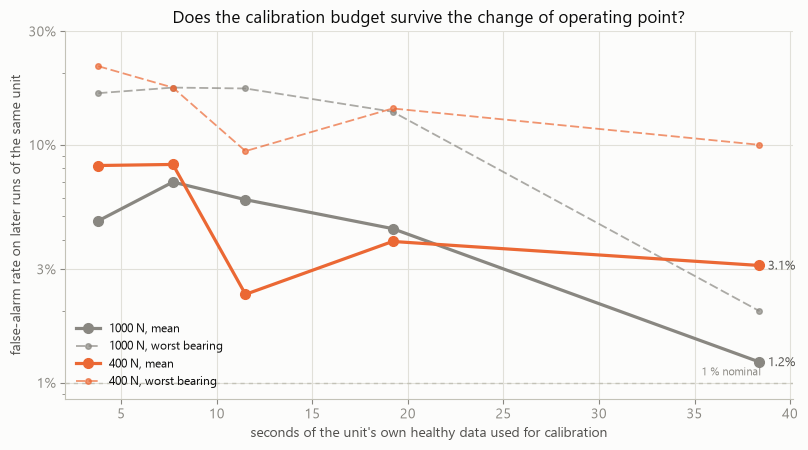

1000 N: 10 runs -> 1.2% mean / 2.0% worst   |   BPFO variance: window 3.84 run 0.97 unit 1.55 dB -> unit is 13.3%
400 N: 10 runs -> 3.1% mean / 10.0% worst   |   BPFO variance: window 3.73 run 0.97 unit 1.82 dB -> unit is 18.1%


In [4]:
def budget(cond):
    rows = []
    d = D[cond]
    for k in (1, 2, 3, 5, 10):
        fa = []
        for h in HEALTHY:
            cal = d[(d["Code"] == h) & (d["Run"] <= k)][BANDS].to_numpy()
            te = d[(d["Code"] == h) & (d["Run"] > k)][BANDS].to_numpy()
            b = fit(cal)
            fa.append((score(te, b) > np.quantile(score(cal, b), 0.99)).mean())
        rows.append(dict(runs=k, seconds=round(k * 3.84, 1),
                         mean=np.mean(fa), worst=np.max(fa)))
    return pd.DataFrame(rows)


def variance_split(cond, feat="Env_BPFO_dB"):
    d = D[cond]
    sw, sr, mu = [], [], []
    for _, g in d[d["Domain"] == "healthy"].groupby("Code"):
        rm = g.groupby("Run")[feat].mean()
        sw.append(g.groupby("Run")[feat].std().mean())
        sr.append(rm.std())
        mu.append(rm.mean())
    w, r, u = np.mean(sw), np.mean(sr), np.std(mu, ddof=1)
    return w, r, u, u ** 2 / (w ** 2 + r ** 2 + u ** 2)


buds = {c: budget(c) for c in (HI, LO)}
fig, ax = plt.subplots(figsize=(8.2, 4.6))
for cond in (HI, LO):
    b = buds[cond]
    ax.plot(b["seconds"], b["mean"], color=LOAD_COLOR[cond], lw=2.3, marker="o", ms=7,
            label=f"{TAG[cond]}, mean")
    ax.plot(b["seconds"], b["worst"], color=LOAD_COLOR[cond], lw=1.3, ls=(0, (5, 2)),
            marker="o", ms=4, alpha=0.7, label=f"{TAG[cond]}, worst bearing")
    ax.annotate(f"{b['mean'].iloc[-1]:.1%}", (b["seconds"].iloc[-1], b["mean"].iloc[-1]),
                textcoords="offset points", xytext=(6, -3), fontsize=9, color=INK2)
ax.axhline(0.01, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(38.5, 0.0105, "1 % nominal", color=MUTED, fontsize=8, ha="right", va="bottom")
ax.set_yscale("log")
ax.set_yticks([0.01, 0.03, 0.1, 0.3], ["1%", "3%", "10%", "30%"])
ax.set_xlabel("seconds of the unit's own healthy data used for calibration")
ax.set_ylabel("false-alarm rate on later runs of the same unit")
ax.set_title("Does the calibration budget survive the change of operating point?")
ax.legend(fontsize=8.5, loc="lower left")
plt.tight_layout()
plt.show()

for cond in (HI, LO):
    b = buds[cond].iloc[-1]
    w, r, u, share = variance_split(cond)
    print(f"{TAG[cond]}: 10 runs -> {b['mean']:.1%} mean / {b['worst']:.1%} worst   |   "
          f"BPFO variance: window {w:.2f} run {r:.2f} unit {u:.2f} dB "
          f"-> unit is {share:.1%}")
scorecard.append(("~38 s of own-unit data gives ~1 % false alarms", "nb08",
                  f"{buds[HI]['mean'].iloc[-1]:.1%} mean / {buds[HI]['worst'].iloc[-1]:.1%} worst",
                  f"{buds[LO]['mean'].iloc[-1]:.1%} mean / {buds[LO]['worst'].iloc[-1]:.1%} worst",
                  "condition-dependent"))
scorecard.append(("Unit-to-unit spread is ~13 % of healthy variance", "nb08",
                  f"{variance_split(HI)[3]:.1%}", f"{variance_split(LO)[3]:.1%}", "robust"))

## Reading claim E — the one number that does not survive

- **The calibration budget is worse at the operating point you would use.**
  Ten records give **3.1 % mean / 10.0 % worst-case** false alarms at 400 N,
  against 1.2 % / 2.0 % at 1000 N. The headline "≈ 38 seconds buys 1 %" was
  measured at the condition that happens to be kindest to it.
- The variance split explains why: unit-to-unit spread rises from **13.3 % to
  18.1 %** of the healthy variance at BPFO (σ_unit 1.55 → 1.82 dB) while window
  and run noise are unchanged. Lighter loading lets each unit's own
  installation character show through more.
- Practical correction: **budget more than ten records at low load, or accept
  ≈ 3 %.** The direction of notebook 08's advice is intact — own-unit data is
  still worth orders of magnitude over a borrowed baseline — but the specific
  figure now carries an operating point with it, and `problem-statement.md`
  should say so.
- Notebook 08's structural claim (unit-to-unit is a minority of the variance,
  so calibration is a false-alarm fix rather than a sensitivity fix) is
  **robust** at both loads.

## The thing notebook 09 could not see: detected is not diagnosed

Notebook 09 scored **missed faults** — windows predicted `Healthy` when the
bearing is damaged. That is the safety-critical metric and it improved
dramatically at 400 N. But a three-class problem has a second failure mode
that metric cannot show: a bearing detected as faulty and assigned to the
**wrong race**. Splitting the prediction three ways settles what the low-load
gain actually bought.

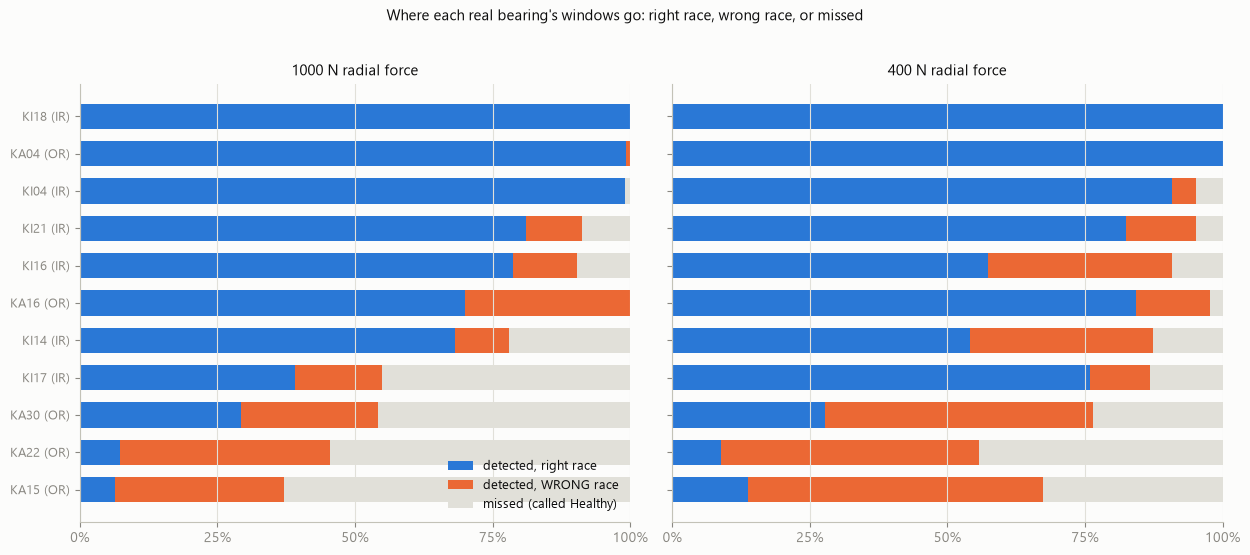

            1000 N  400 N
detected     0.773  0.866
right race   0.617  0.632
wrong race   0.156  0.234

confusion at 1000 N (row = true race, column = predicted):
    Healthy     OR     IR
OR    0.327  0.424  0.249
IR    0.144  0.079  0.777

confusion at 400 N (row = true race, column = predicted):
    Healthy     OR     IR
OR    0.205  0.469  0.325
IR    0.074  0.158  0.768

OR called IR: 24.9% -> 32.5%   |   IR called OR: 7.9% -> 15.8%

the four problem bearings:
  KA15 (OR): detected 37.1% -> 67.3%   right race 6.4% -> 13.8%   wrong race 30.7% -> 53.5%
  KA22 (OR): detected 45.4% -> 55.8%   right race 7.3% -> 8.9%   wrong race 38.2% -> 46.9%
  KA30 (OR): detected 54.1% -> 76.4%   right race 29.2% -> 27.8%   wrong race 24.9% -> 48.7%
  KI17 (IR): detected 54.9% -> 86.8%   right race 39.1% -> 75.9%   wrong race 15.8% -> 10.9%


In [5]:
def split_outcomes(cond):
    d = D[cond]
    det = {c: [] for c in REAL}
    right = {c: [] for c in REAL}
    wrong = {c: [] for c in REAL}
    for h in HEALTHY:
        tr = d[((d["Domain"] == "healthy") & (d["Code"] != h)) | (d["Domain"] == "artificial")]
        m = RandomForestClassifier(**RF_KW).fit(tr[FUND], tr["Condition"])
        for c in REAL:
            p = m.predict(d[d["Code"] == c][FUND])
            true = LABEL.loc[c, "Condition"]
            det[c].append((p != "Healthy").mean())
            right[c].append((p == true).mean())
            wrong[c].append(((p != "Healthy") & (p != true)).mean())
    return pd.DataFrame({"detected": {k: np.mean(v) for k, v in det.items()},
                         "right race": {k: np.mean(v) for k, v in right.items()},
                         "wrong race": {k: np.mean(v) for k, v in wrong.items()}})


def confusion(cond):
    """Row = true race, column = predicted, as a fraction of that race's windows."""
    d = D[cond]
    tally = pd.DataFrame(0.0, index=["OR", "IR"], columns=["Healthy", "OR", "IR"])
    n = {"OR": 0, "IR": 0}
    for h in HEALTHY:
        tr = d[((d["Domain"] == "healthy") & (d["Code"] != h)) | (d["Domain"] == "artificial")]
        m = RandomForestClassifier(**RF_KW).fit(tr[FUND], tr["Condition"])
        for c in REAL:
            p = m.predict(d[d["Code"] == c][FUND])
            true = LABEL.loc[c, "Condition"]
            for lab in ("Healthy", "OR", "IR"):
                tally.loc[true, lab] += (p == lab).sum()
            n[true] += len(p)
    return tally.div([n["OR"], n["IR"]], axis=0)


out = {c: split_outcomes(c) for c in (HI, LO)}
conf = {c: confusion(c) for c in (HI, LO)}
order = out[HI].sort_values("right race").index

fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.4), sharey=True)
for ax, cond in zip(axes, (HI, LO)):
    o = out[cond].loc[order]
    y = np.arange(len(order))
    ax.barh(y, o["right race"], color=C_BLUE, height=0.68, label="detected, right race")
    ax.barh(y, o["wrong race"], left=o["right race"], color=C_ORANGE, height=0.68,
            label="detected, WRONG race")
    ax.barh(y, 1 - o["detected"], left=o["detected"], color=GRID, height=0.68,
            label="missed (called Healthy)")
    ax.set_xlim(0, 1)
    ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{TAG[cond]} radial force", fontsize=10.5)
axes[0].set_yticks(np.arange(len(order)),
                   [f"{b} ({LABEL.loc[b, 'Condition']})" for b in order], fontsize=9)
axes[0].legend(fontsize=9, loc="lower right")
fig.suptitle("Where each real bearing's windows go: right race, wrong race, or missed",
             fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({TAG[c]: out[c].mean() for c in (HI, LO)})
print(summary.round(3).to_string())
for cond in (HI, LO):
    print(f"\nconfusion at {TAG[cond]} (row = true race, column = predicted):")
    print(conf[cond].round(3).to_string())
print(f"\nOR called IR: {conf[HI].loc['OR', 'IR']:.1%} -> {conf[LO].loc['OR', 'IR']:.1%}   |   "
      f"IR called OR: {conf[HI].loc['IR', 'OR']:.1%} -> {conf[LO].loc['IR', 'OR']:.1%}")
print("\nthe four problem bearings:")
for b in PROBLEM:
    a, z = out[HI].loc[b], out[LO].loc[b]
    print(f"  {b} ({LABEL.loc[b, 'Condition']}): detected {a['detected']:.1%} -> {z['detected']:.1%}"
          f"   right race {a['right race']:.1%} -> {z['right race']:.1%}"
          f"   wrong race {a['wrong race']:.1%} -> {z['wrong race']:.1%}")
scorecard.append(("Low radial force improves diagnosis", "nb09",
                  f"right race {out[HI]['right race'].mean():.1%}",
                  f"right race {out[LO]['right race'].mean():.1%} "
                  f"(wrong race {out[HI]['wrong race'].mean():.1%} -> "
                  f"{out[LO]['wrong race'].mean():.1%})", "qualified"))

## Reading the split — notebook 09's gain is detection, not diagnosis

- **Across the eleven real bearings, detection rises 77.3 % → 86.6 % while
  correct diagnosis rises only 61.7 % → 63.2 %.** The difference goes to
  **wrong-race attribution, which grows 15.6 % → 23.4 %.** Most of what the
  low-load condition buys is an alarm, not an answer.
- **For the three outer-race problem bearings it is nearly all misattribution.**
  KA15: detected 37 % → 67 %, right race 6 % → 14 %, **wrong race 31 % → 54 %**.
  KA30: detected 54 % → 76 %, right race 29 % → **28 %** (down), wrong race
  25 % → 49 %. KA22: detected 45 % → 56 %, right race 7 % → 9 %.
- **KI17 is the one real diagnostic win**: detected 55 % → 87 %, right race
  39 % → **76 %**, wrong race *down* 16 % → 11 %.
- **The confusion grows in both directions**, which rules out a simple bias.
  OR windows called IR rise 24.9 % → 32.5 %, and IR windows called OR rise
  7.9 % → 15.8 %. The mechanism is the one claims A and B exposed: the recovered
  energy is at **shaft rate**, which separates *faulty from healthy* but carries
  **no race information**. So windows are pulled out of `Healthy` and then land
  on whichever side of the OR/IR boundary the unchanged BPFO/BPFI features put
  them. For KA15, KA22 and KA30 — outer-race bearings with no BPFO elevation at
  either load — there is nothing pushing them toward OR, so IR wins by default:
  53.5 %, 46.9 % and 48.7 % of their windows. Notebook 07's attribution table
  agrees: at 1000 N KA15/KA30/KI17 fire loudest at orders 5.0/3.0/9.0, and at
  400 N **all three fire at order 1.0 — shaft rate**.
- So notebook 09's headline stands as a *safety* result and must be stated as
  one: at 400 N the framework reliably says **"this bearing is not healthy"**,
  and for outer-race indentation damage it still cannot say which race.
  *Detectable ≠ attributable* now applies to 3 of 11 real bearings at **every**
  operating point tested.

## Does splitting the job across operating points help?

If low load detects and nominal load attributes, the obvious protocol is to use
both: raise the alarm from a low-load diagnostic window, then name the fault
from the nominal-load recording. Worth testing rather than assuming — notebook
09 already showed that combining operating points can cost more than it buys.

In [6]:
def majority_race(pred):
    nz = pred[pred != "Healthy"]
    return pd.Series(nz).mode()[0] if len(nz) else "Healthy"


rows = []
for b in REAL + HEALTHY:
    folds = HEALTHY if b in REAL else [b]      # a healthy bearing is only scored on its own fold
    alarm_lo, alarm_hi, race_lo, race_hi = [], [], [], []
    for h in folds:
        pred = {}
        for cond in (LO, HI):
            d = D[cond]
            tr = d[((d["Domain"] == "healthy") & (d["Code"] != h)) | (d["Domain"] == "artificial")]
            pred[cond] = (RandomForestClassifier(**RF_KW).fit(tr[FUND], tr["Condition"])
                          .predict(d[d["Code"] == b][FUND]))
        alarm_lo.append(((pred[LO] != "Healthy").reshape(N_RUN, N_WIN).mean(axis=1) > 0.5).mean())
        alarm_hi.append(((pred[HI] != "Healthy").reshape(N_RUN, N_WIN).mean(axis=1) > 0.5).mean())
        if b in REAL:
            true = LABEL.loc[b, "Condition"]
            race_lo.append(majority_race(pred[LO]) == true)
            race_hi.append(majority_race(pred[HI]) == true)
    rows.append(dict(Code=b, truth=LABEL.loc[b, "Condition"] if b in REAL else "Healthy",
                     alarm_400N=np.mean(alarm_lo), alarm_1000N=np.mean(alarm_hi),
                     race_400N=np.mean(race_lo) if race_lo else np.nan,
                     race_1000N=np.mean(race_hi) if race_hi else np.nan))
proto = pd.DataFrame(rows).set_index("Code")
proto["two_stage"] = proto["alarm_400N"] * proto["race_1000N"]
real, healthy = proto.loc[REAL], proto.loc[HEALTHY]

print("recording-level, per bearing:")
print(proto.round(3).to_string())
print(f"\nreal bearings   : alarm at 400 N {real['alarm_400N'].mean():.1%}   "
      f"at 1000 N {real['alarm_1000N'].mean():.1%}")
print(f"race called right: at 400 N {real['race_400N'].mean():.1%}   "
      f"at 1000 N {real['race_1000N'].mean():.1%}")
print(f"two-stage (alarm at 400 N, race at 1000 N), fully correct: "
      f"{real['two_stage'].mean():.1%}  "
      f"[{int(real['two_stage'].round().sum())} of {len(REAL)} bearings]")
print(f"false alarm on an unseen healthy bearing: 400 N "
      f"{healthy['alarm_400N'].mean():.1%}   1000 N {healthy['alarm_1000N'].mean():.1%}")
print("\nbearings the two-stage protocol still fails:",
      sorted(real.index[real["two_stage"] < 0.5]))

recording-level, per bearing:
        truth  alarm_400N  alarm_1000N  race_400N  race_1000N  two_stage
Code                                                                    
KA04       OR       1.000        1.000        1.0         1.0        1.0
KA15       OR       0.942        0.175        0.0         0.0        0.0
KA16       OR       1.000        1.000        1.0         1.0        1.0
KA22       OR       0.725        0.275        0.0         0.0        0.0
KA30       OR       1.000        0.625        0.0         1.0        1.0
KI04       IR       1.000        1.000        1.0         1.0        1.0
KI14       IR       1.000        1.000        1.0         1.0        1.0
KI16       IR       1.000        1.000        1.0         1.0        1.0
KI17       IR       1.000        0.675        1.0         1.0        1.0
KI18       IR       1.000        1.000        1.0         1.0        1.0
KI21       IR       1.000        1.000        1.0         1.0        1.0
K001  Healthy       0

## Reading the two-stage protocol

- **It works, and it is the best result this project has produced.** Alarm from
  the 400 N window (**97.0 %** of real-damage recordings, **8.3 %** false alarms
  on an unseen healthy bearing), then name the race from the 1000 N recording
  (**81.8 %** correct): **9 of 11 real bearings fully correct**.
- **KA30 is the proof of the idea.** Its race is called correctly at 1000 N and
  wrongly at 400 N — the two loads are genuinely good at different halves of
  the job, and using each for its half beats using either alone.
- **The two failures are KA15 and KA22**, which no operating point attributes
  correctly. That is now a stable, well-characterised residue rather than an
  open question: one is indentation damage that never excites a ball-pass
  frequency, the other rings at a non-tracking structural line.
- This is a stronger argument for a *twin* than anything the project has had.
  The framework does not merely observe a motor; it **commands an operating
  point for the purpose of diagnosis**, and commands a different one for
  attribution. That is bidirectional in the sense the Model/Shadow/Twin
  distinction requires (`RESEARCH_NOTES.md` §2), and it is a control policy the
  digital twin can be asked to optimise.

In [7]:
card = pd.DataFrame(scorecard, columns=["claim", "source", f"at {TAG[HI]}", f"at {TAG[LO]}",
                                        "verdict"]).set_index("claim")
VERDICT_BG = {"robust": "#e8f1fb", "robust, wider": "#e8f1fb",
              "condition-dependent": "#fdeee6", "qualified": "#fdeee6"}
card.style.apply(lambda s: [f"background-color: {VERDICT_BG.get(v, '')}" for v in s],
                 subset=["verdict"])

,source,at 1000 N,at 400 N,verdict
claim,,,,
"KA22's energy sits at ~5.75 x fr, not at BPFO",nb06,14.3 dB vs 1.6 at BPFO,13.0 dB vs 1.1 at BPFO,robust
KA15/KA30 do not ring at BPFO,nb06,KA15 1.0 dB,KA15 2.0 dB,robust
Healthy bearings form two installation-signature groups,nb07,median pair distance 2.88 dB,"2.69 dB, same grouping",robust
3 fundamentals beat 59 order bands as an anomaly score,nb07,47.8% vs 38.7%,50.4% vs 21.3%,"robust, wider"
~38 s of own-unit data gives ~1 % false alarms,nb08,1.2% mean / 2.0% worst,3.1% mean / 10.0% worst,condition-dependent
Unit-to-unit spread is ~13 % of healthy variance,nb08,13.3%,18.1%,robust
Low radial force improves diagnosis,nb09,right race 61.7%,right race 63.2% (wrong race 15.6% -> 23.4%),qualified


## Findings (executed 2026-08-20)

1. **Most of notebooks 06–08 survives the change of operating point.** Five of
   seven re-tested claims are robust: KA22's off-frequency line, KA15/KA30's
   silence at BPFO, the two-population healthy split, the fundamentals beating
   59 order bands, and unit-to-unit spread being a minority of healthy
   variance. These are properties of the bearings and the rig, not of the
   condition that happened to be analysed.
2. **The 59-band anomaly detector gets *worse* at the better operating point**
   (38.7 % → 21.3 % detection at 1 % false alarms) while the three fundamentals
   improve (47.8 % → 50.4 %). The gap widens from 9 to 29 points: at low load
   the useful energy concentrates into the fundamentals while the
   high-unit-variance rig-harmonic bands do not move.
3. **The calibration budget is the one number that does not survive.** Ten
   own-unit records give **3.1 % mean / 10.0 % worst** false alarms at 400 N
   against 1.2 % / 2.0 % at 1000 N, because unit-to-unit spread rises from
   13.3 % to 18.1 % of the healthy variance. Notebook 08's "≈ 38 seconds buys
   1 %" was measured at the condition kindest to it and must be quoted with
   its operating point.
4. **Notebook 09's low-load gain is detection, not diagnosis.** Across eleven
   real bearings, detection rises 77.3 % → 86.6 % but correct diagnosis only
   61.7 % → 63.2 %; the difference becomes **wrong-race attribution, 15.6 % →
   23.4 %**. For the three outer-race problem bearings it is almost entirely
   misattribution (KA15 wrong race 31 % → 54 %; KA30 right race 29 % → 28 %).
   KI17 is the single genuine diagnostic win (right race 39 % → 76 %).
5. **The cause is that the recovered energy is at shaft rate.** KA15's
   shaft-rate SNR goes +3.0 → +5.8 dB and KA30's +3.3 → +5.4 dB while BPFO
   barely moves; the anomaly attribution shifts to order 1.0 for KA15, KA30 and
   KI17. Shaft rate separates faulty from healthy but carries **no race
   information**, so recovered windows scatter across both classes — confusion
   rises in *both* directions (OR called IR 24.9 % → 32.5 %; IR called OR 7.9 %
   → 15.8 %), and the three outer-race bearings with no BPFO elevation land on
   IR by default. **Detectable ≠ attributable now applies to 3 of 11 real
   bearings at every operating point tested.**
6. **A two-stage protocol is the best result the project has produced**: alarm
   from a 400 N diagnostic window (**97.0 %** of real-damage recordings,
   **8.3 %** false alarms on an unseen healthy bearing), attribute from the
   1000 N recording (**81.8 %** correct race) — **9 of 11 bearings fully
   correct**, failing only on KA15 and KA22. KA30 is diagnosed correctly at
   1000 N and wrongly at 400 N, which is the mechanism working as designed.
7. **This is the project's strongest "twin" argument.** A framework that
   commands one operating point to detect and another to attribute is
   bidirectional in the Model/Shadow/Twin sense, and the choice of operating
   points is a control policy the twin can optimise.
8. **Caveats:** two radial-force levels on one rig, so the low-load result is a
   direction rather than a dose-response; the two-stage protocol assumes both
   operating points are reachable on demand, which is a real constraint on a
   production motor; single classifier family (RF) and the three envelope
   fundamentals throughout.